In [39]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder,StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error,r2_score

In [40]:
df = pd.read_csv('/home/kapil/Documents/WorkPlace/Machine_learning/house-rent-prediction/data/House_Rent_Dataset.csv')


In [41]:
print(df.head())
print(df.shape)
print(df.info())

    Posted_On  BHK   Rent  Size            Floor    Area_Type  \
0  2022-05-18    2  10000  1100  Ground out of 2   Super Area   
1  2022-05-13    2  20000   800       1 out of 3   Super Area   
2  2022-05-16    2  17000  1000       1 out of 3   Super Area   
3  2022-07-04    2  10000   800       1 out of 2   Super Area   
4  2022-05-09    2   7500   850       1 out of 2  Carpet Area   

              Area_Locality     City Furnishing_Status  Tenant_Preferred  \
0                    Bandel  Kolkata       Unfurnished  Bachelors/Family   
1  Phool Bagan, Kankurgachi  Kolkata    Semi-Furnished  Bachelors/Family   
2   Salt Lake City Sector 2  Kolkata    Semi-Furnished  Bachelors/Family   
3               Dumdum Park  Kolkata       Unfurnished  Bachelors/Family   
4             South Dum Dum  Kolkata       Unfurnished         Bachelors   

   Bathroom Point_of_Contact  
0         2    Contact Owner  
1         1    Contact Owner  
2         1    Contact Owner  
3         1    Contact Owner

In [42]:
X = df.drop(["Rent", "Posted_On"], axis=1)
y = df["Rent"]

In [43]:
df.columns = df.columns.str.strip()
print(df.columns)

Index(['Posted_On', 'BHK', 'Rent', 'Size', 'Floor', 'Area_Type',
       'Area_Locality', 'City', 'Furnishing_Status', 'Tenant_Preferred',
       'Bathroom', 'Point_of_Contact'],
      dtype='str')


In [44]:
numerical_column = X.select_dtypes(include=["int64","float64"]).columns
categorical_columns =X.select_dtypes(include=["object"]).columns

/tmp/ipykernel_137163/4021355529.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns =X.select_dtypes(include=["object"]).columns


In [45]:
print("numerical_column: ")
print(list(numerical_column))

numerical_column: 
['BHK', 'Size', 'Bathroom']


In [46]:
print("categorical_columns: ")
print(list(categorical_columns))

categorical_columns: 
['Floor', 'Area_Type', 'Area_Locality', 'City', 'Furnishing_Status', 'Tenant_Preferred', 'Point_of_Contact']


In [47]:
numeric_pipeline = Pipeline([
    ("imputer",SimpleImputer(strategy="median")),
    ("scale",StandardScaler())
])

In [48]:
categorical_pipline = Pipeline([
    ("impute",SimpleImputer(strategy="most_frequent")),
    ("encoder",OneHotEncoder(handle_unknown="ignore",sparse_output=False))
])

In [49]:
preprocessor = ColumnTransformer([
    ("num",numeric_pipeline,numerical_column),
    ("cat",categorical_pipline,categorical_columns)
])

In [50]:
model = Pipeline([
    ("preprocessor",preprocessor),
    ("regressor",LinearRegression())
])

In [51]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42)

In [52]:
model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['BHK','Size','Floor',...,'Tenant_Preferred','Bathroom','Point_of_Contact']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of

In [53]:
y_pred = model.predict(X_test)

In [54]:
mae = mean_absolute_error(y_test,y_pred)
mse = mean_squared_error(y_test,y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test,y_pred)

In [55]:
print("MAE",mae)
print("MSE",mse)
print(rmse)
print(r2)

MAE 31730.892827644286
MSE 6025682323.615964
77625.26858965425
-0.511946246561408


In [56]:
print("R2 Percentage ", r2*100, "%")

R2 Percentage  -51.194624656140796 %


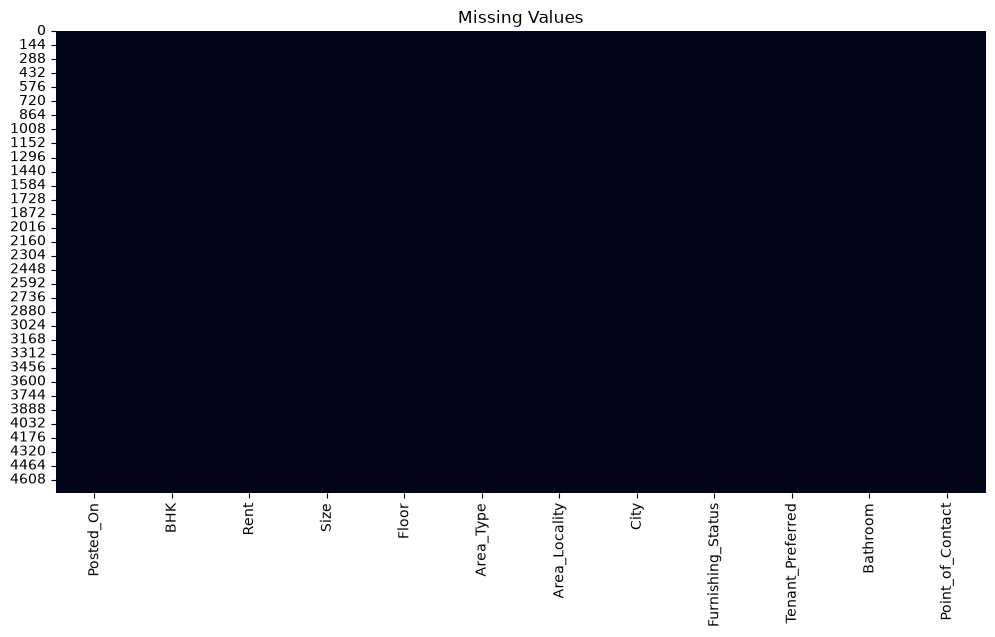

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
plt.figure(figsize=(12,6))
sns.heatmap(df.isnull(),cbar=False)
plt.title("Missing Values")
plt.show()

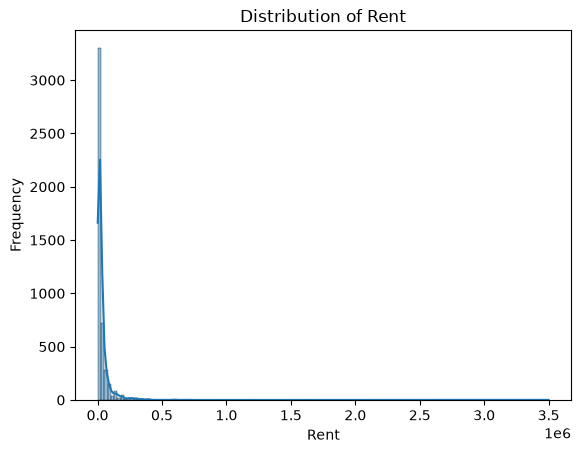

In [58]:
plt.Figure(figsize=(10,6))
sns.histplot(df["Rent"],kde=True)
plt.title("Distribution of Rent")
plt.xlabel("Rent")
plt.ylabel("Frequency")
plt.show()

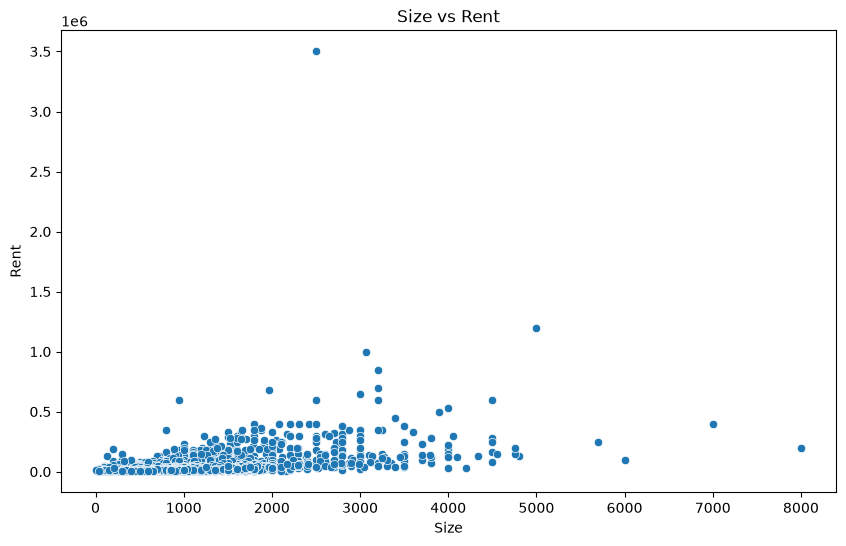

In [59]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df,x="Size",y="Rent")
plt.title("Size vs Rent")
plt.xlabel("Size")
plt.ylabel("Rent")
plt.show()

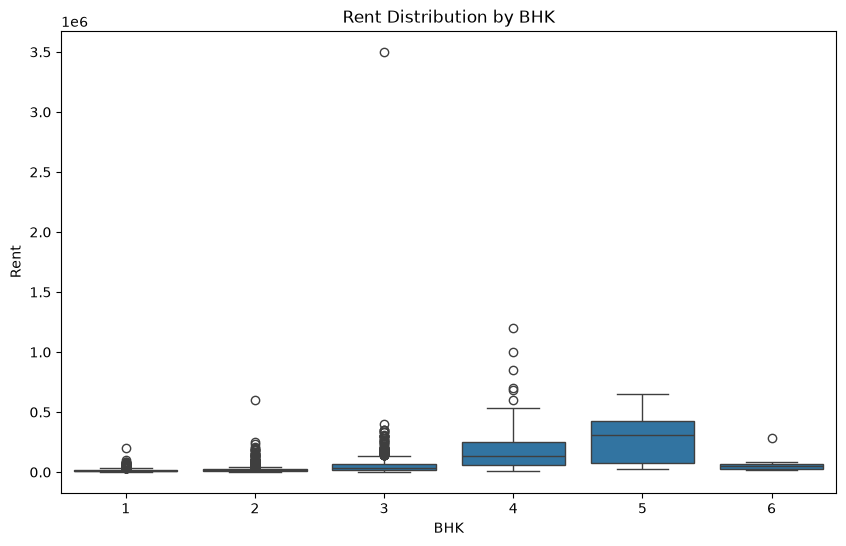

In [60]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="BHK", y="Rent")

plt.title("Rent Distribution by BHK")
plt.xlabel("BHK")
plt.ylabel("Rent")
plt.show()

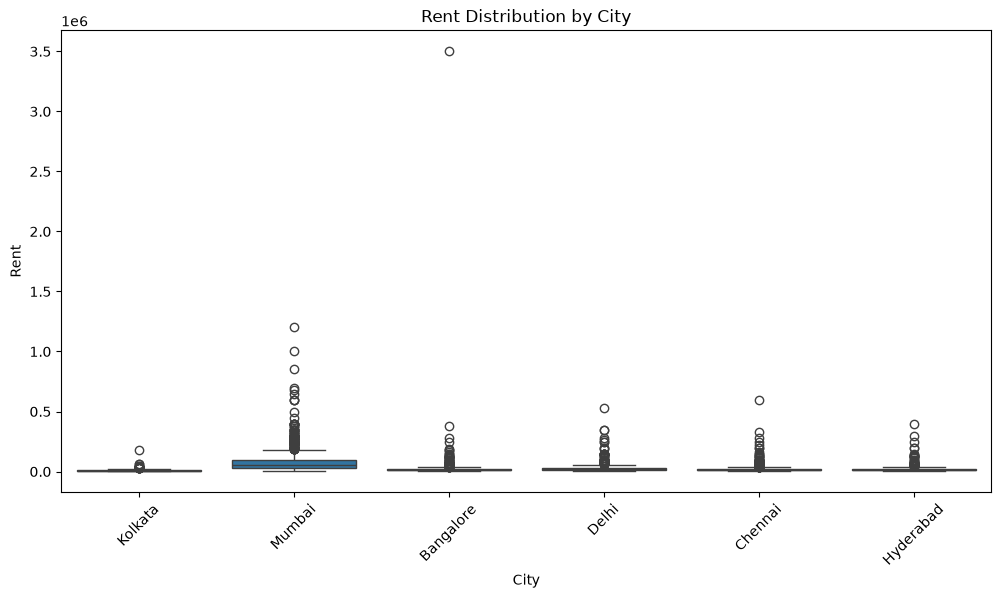

In [61]:
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="City", y="Rent")

plt.title("Rent Distribution by City")
plt.xlabel("City")
plt.ylabel("Rent")

plt.xticks(rotation=45)
plt.show()

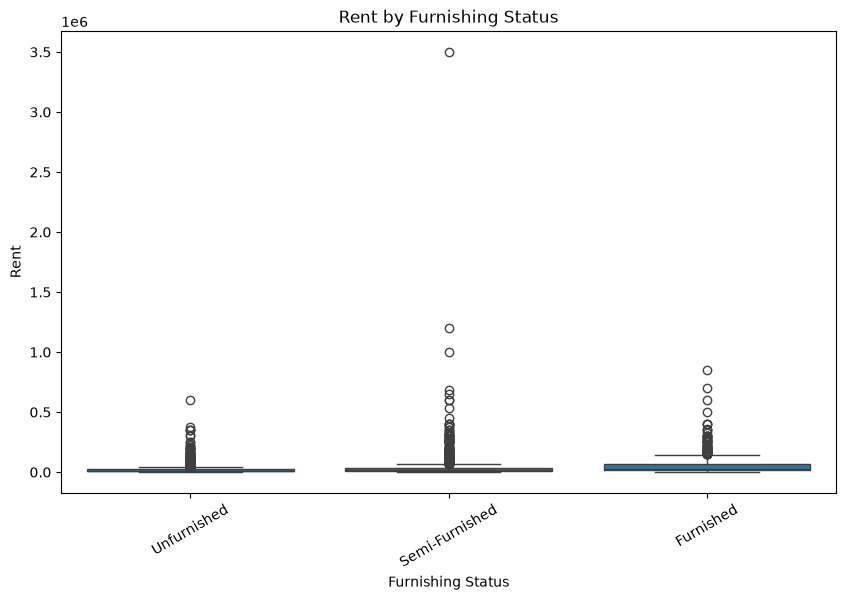

In [62]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Furnishing_Status", y="Rent")

plt.title("Rent by Furnishing Status")
plt.xlabel("Furnishing Status")
plt.ylabel("Rent")

plt.xticks(rotation=30)
plt.show()

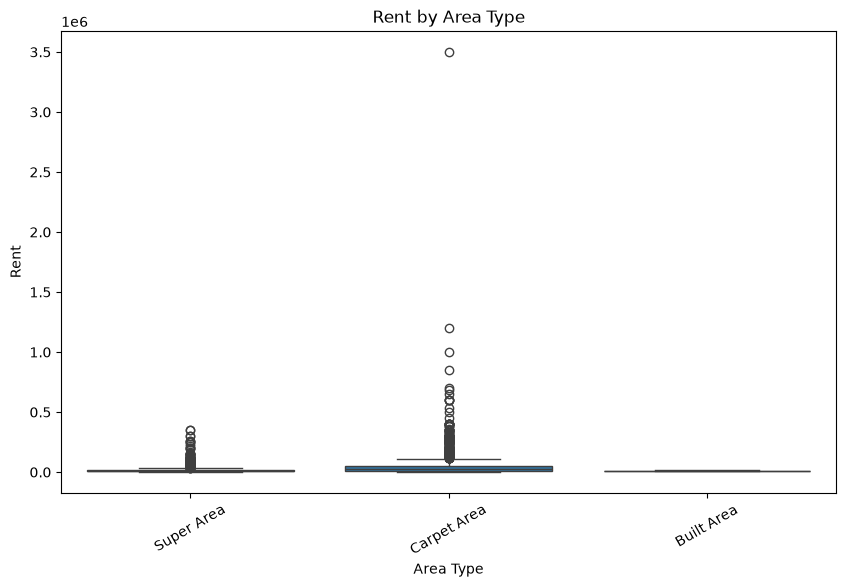

In [63]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Area_Type", y="Rent")

plt.title("Rent by Area Type")
plt.xlabel("Area Type")
plt.ylabel("Rent")

plt.xticks(rotation=30)
plt.show()

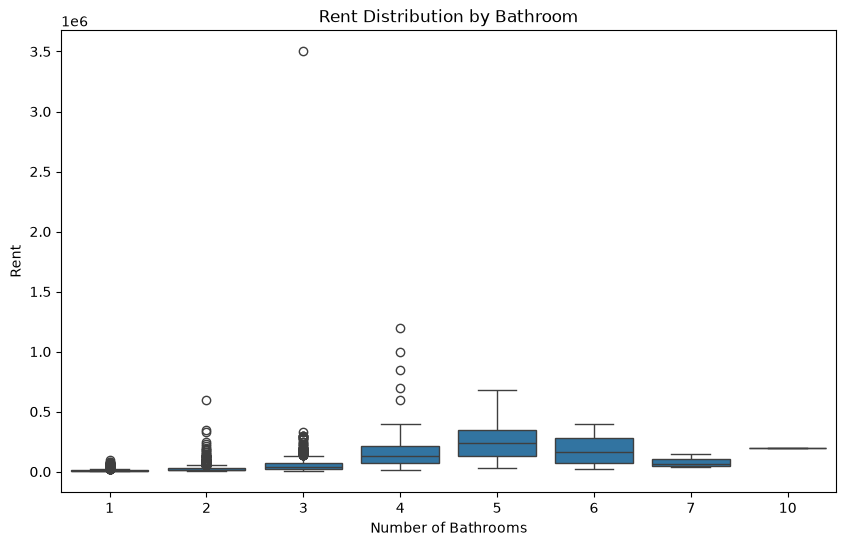

In [64]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=df, x="Bathroom", y="Rent")

plt.title("Rent Distribution by Bathroom")
plt.xlabel("Number of Bathrooms")
plt.ylabel("Rent")
plt.show()

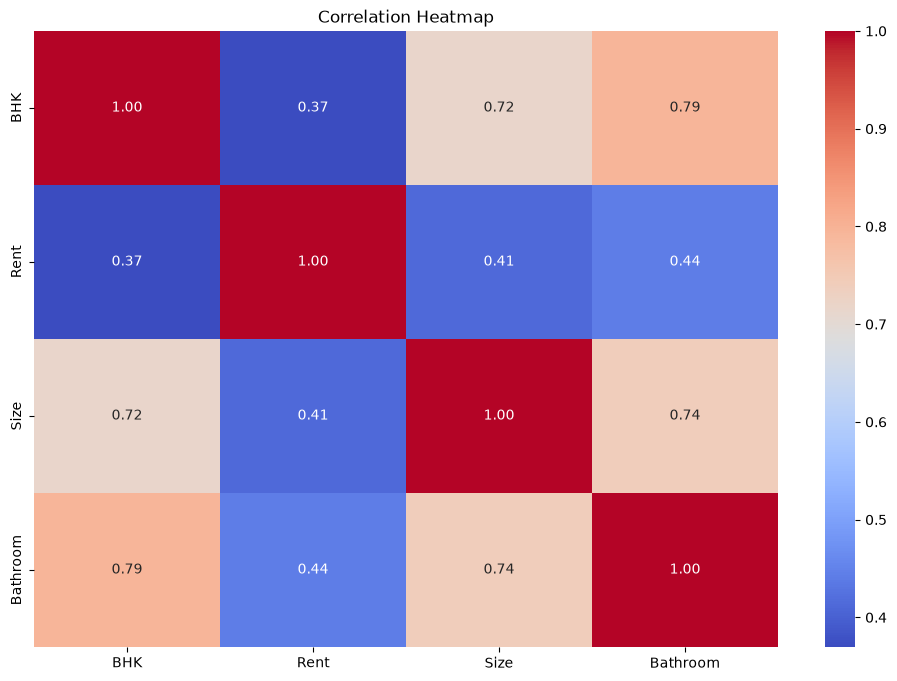

In [65]:
plt.figure(figsize=(12, 8))

numeric_df = df.select_dtypes(include=["number"])

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

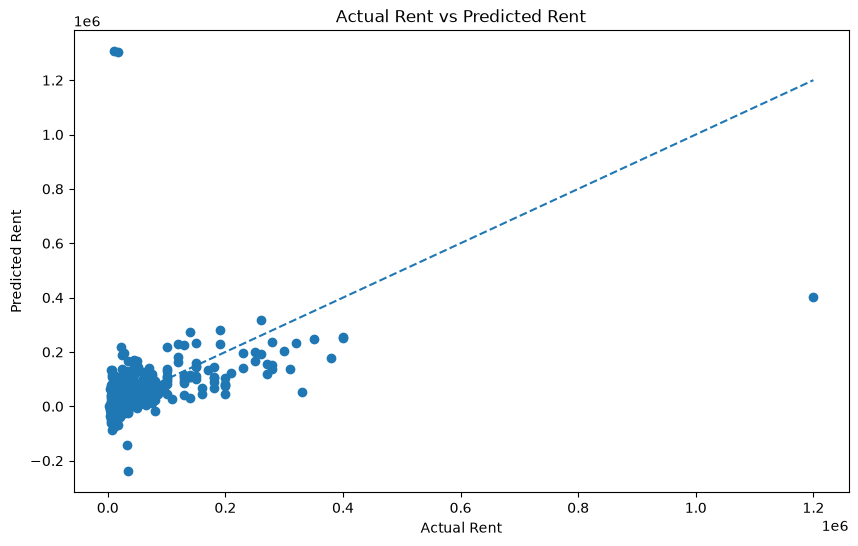

In [66]:
plt.figure(figsize=(10, 6))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Rent")
plt.ylabel("Predicted Rent")
plt.title("Actual Rent vs Predicted Rent")

# Perfect prediction line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.show()

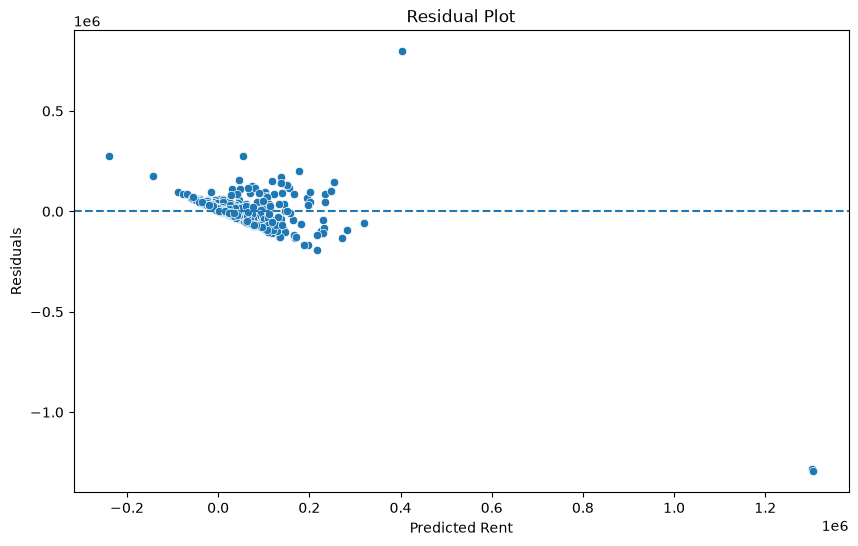

In [67]:
residuals = y_test - y_pred

plt.figure(figsize=(10, 6))

sns.scatterplot(x=y_pred, y=residuals)

plt.axhline(0, linestyle="--")

plt.xlabel("Predicted Rent")
plt.ylabel("Residuals")
plt.title("Residual Plot")

plt.show()

In [68]:
import joblib

joblib.dump(model, "../model/rent_model.pkl")

['../model/rent_model.pkl']